# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [18]:
# Import necessary libraries

# General 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random
import pathlib
import json
import re
from collections import Counter
from PIL import Image

import tensorflow as tf
import keras
from keras import layers, models, regularizers
from keras.applications import MobileNetV2
from keras.layers import TextVectorization, Embedding
from keras.utils import load_img, img_to_array
from keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sentence_transformers import SentenceTransformer
from transformers import pipeline

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

In [2]:
# Dataset path
DATASET_PATH = "./realwaste-main/RealWaste/"

# Get waste categories
categories = os.listdir(DATASET_PATH)

# Count images in each category
category_counts = {}

for category in categories:
    category_path = os.path.join(DATASET_PATH, category)

    if os.path.isdir(category_path):
        images = os.listdir(category_path)
        category_counts[category] = len([
            img for img in images
            if img.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

# Create DataFrame
category_df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Image Count"]
)

print("Number of Categories:", len(category_df))
print("Total Images:", category_df["Image Count"].sum())

display(category_df)

Number of Categories: 9
Total Images: 4752


,Category,Image Count
0,Paper,500
1,Metal,790
2,Cardboard,461
3,Food Organics,411
4,Glass,420
5,Vegetation,436
6,Textile Trash,318
7,Miscellaneous Trash,495
8,Plastic,921


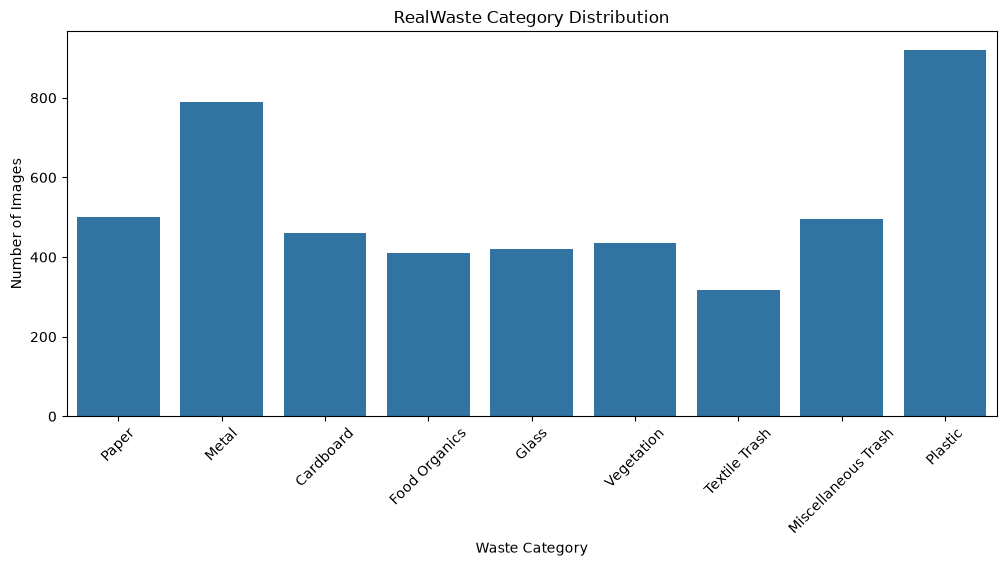

In [3]:
# - Distribution of waste categories

plt.figure(figsize=(12, 5))
sns.barplot(data=category_df, x="Category", y="Image Count")
plt.title("RealWaste Category Distribution")
plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [4]:
# - Image characteristics (resolution, quality, background)
# image resolution distribution

# Collect image dimensions
image_info = []

for category in categories:
    category_path = os.path.join(DATASET_PATH, category)

    if not os.path.isdir(category_path):
        continue

    for filename in os.listdir(category_path):
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            image_path = os.path.join(category_path, filename)

            with Image.open(image_path) as img:
                width, height = img.size
                image_info.append([width, height])

# Create DataFrame
image_df = pd.DataFrame(image_info, columns=["Width", "Height"])

# Display image statistics
display(image_df.describe())

,Width,Height
count,4752.0,4752.0
mean,524.0,524.0
std,0.0,0.0
min,524.0,524.0
25%,524.0,524.0
50%,524.0,524.0
75%,524.0,524.0
max,524.0,524.0


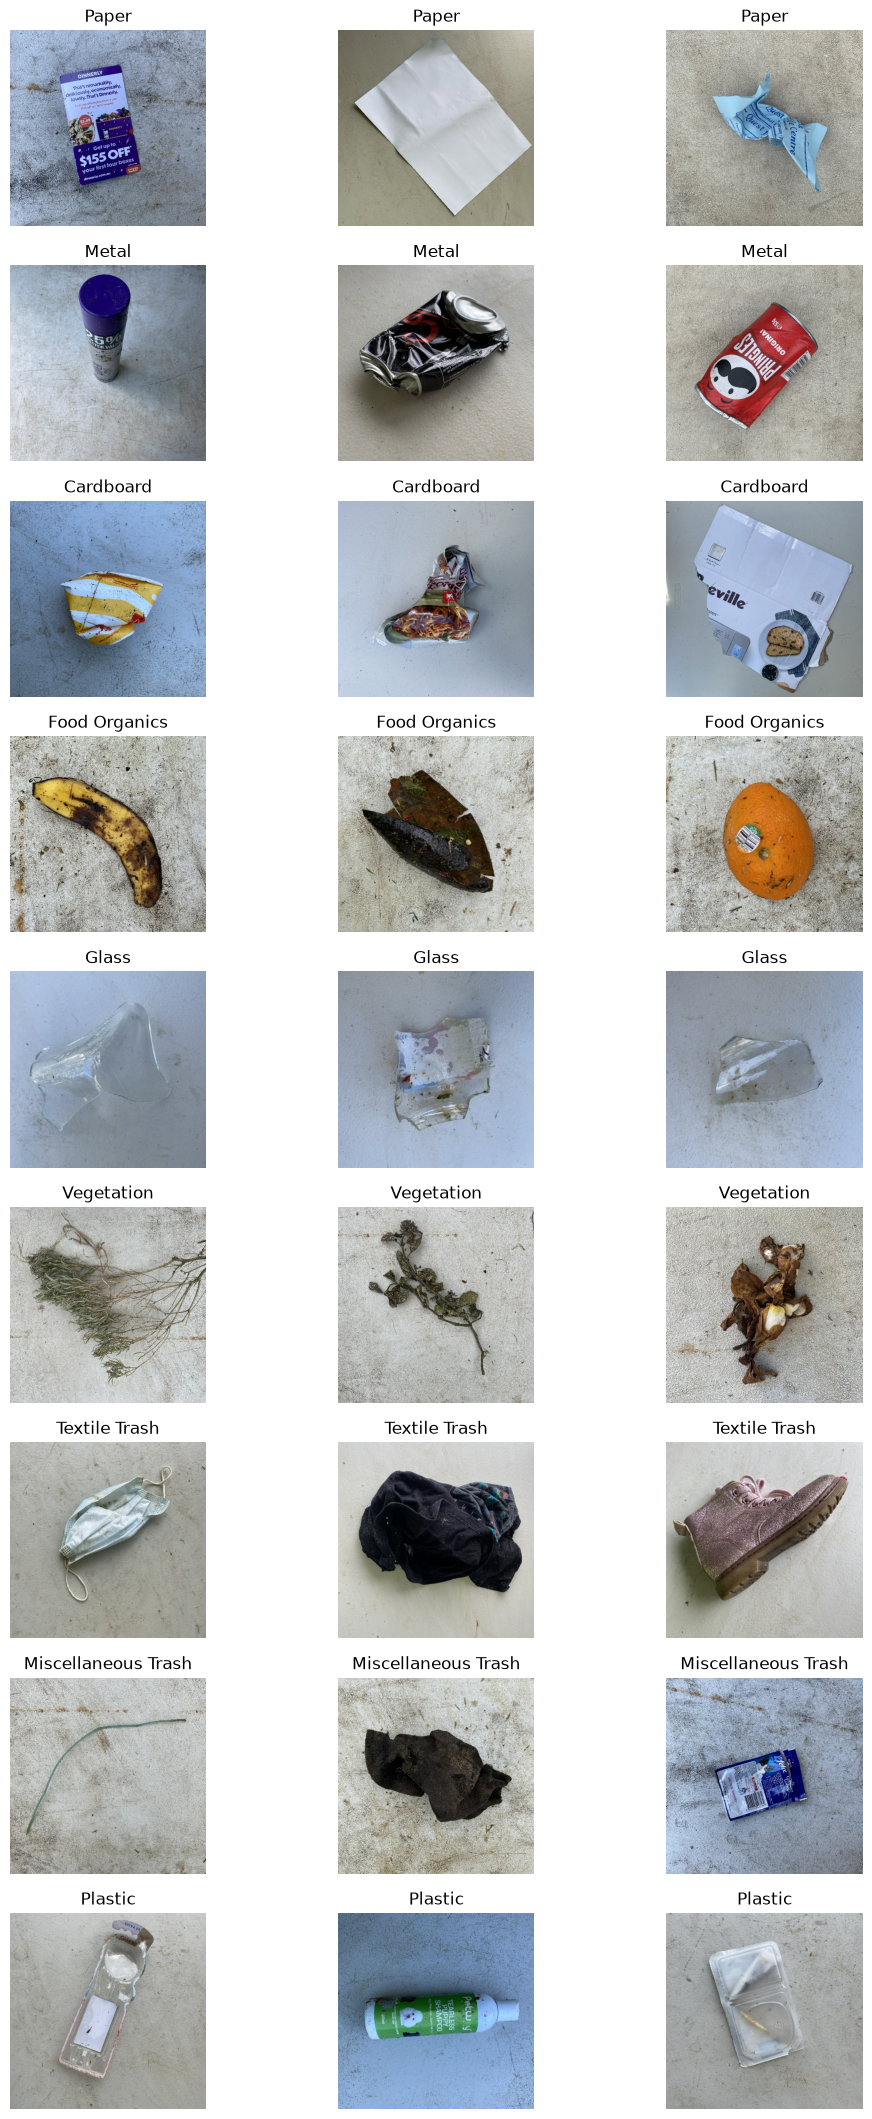

In [5]:
# sample images

# Display 3 sample images from each category
plt.figure(figsize=(12, 3 * len(category_df)))

for i, category in enumerate(category_df["Category"]):
    category_path = os.path.join(DATASET_PATH, category)

    images = [
        img for img in os.listdir(category_path)
        if img.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    sample_images = random.sample(images, min(3, len(images)))

    for j, filename in enumerate(sample_images):
        image_path = os.path.join(category_path, filename)

        img = Image.open(image_path)

        plt.subplot(len(category_df), 3, i * 3 + j + 1)
        plt.imshow(img)
        plt.title(category)
        plt.axis("off")

plt.show()

### 1.2 Explore Text Datasets

In [6]:
# TODO: Load and explore the waste description text data
# - Load waste_descriptions.csv
text_df = pd.read_csv("waste_descriptions.csv")

text_df.head(10)

,description,category,disposal_instruction,common_confusion,material_composition
0,soiled silver tablecloth,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
1,folded glass bottle leaking,Glass,"Remove caps, lids, and corks before recycling.",NaN,"Silica-based material, may contain additives f..."
2,large Supermarket vegetable waste with food re...,Food Organics,"If no compost available, place in general waste.",NaN,Biodegradable matter derived from plant or ani...
3,intact floral carpet piece,Textile Trash,Look for textile recycling programs in your area.,NaN,"Fabric made from natural or synthetic fibers, ..."
4,empty fun-sized purple apple core,Food Organics,Keep separate from recyclable materials.,Meat and dairy products may be restricted in s...,Biodegradable matter derived from plant or ani...
5,wrinkled pink takeout container with product r...,Plastic,Remove labels if possible.,Plastic bags often can not go in general recyc...,Polymer materials derived from petrochemicals ...
6,broken glass container,Glass,"Remove caps, lids, and corks before recycling.","Window glass, drinking glasses, and ceramics s...","Silica-based material, may contain additives f..."
7,clean red grass clippings,Vegetation,Large branches may need to be cut to appropria...,NaN,Plant matter composed primarily of cellulose a...
8,Designer egg carton,Cardboard,"If contaminated with food, tear off contaminat...",Pizza boxes with food stains should go in orga...,Thick paper pulp formed into corrugated or sol...
9,wrinkled metal cutlery with food residue,Metal,"For aerosol cans, ensure they are completely e...",NaN,"Aluminum, steel, tin or mixed metal alloys."


Description Length Statistics:


count    5000.000000
mean        4.854000
std         1.549956
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        10.000000
Name: word_count, dtype: float64

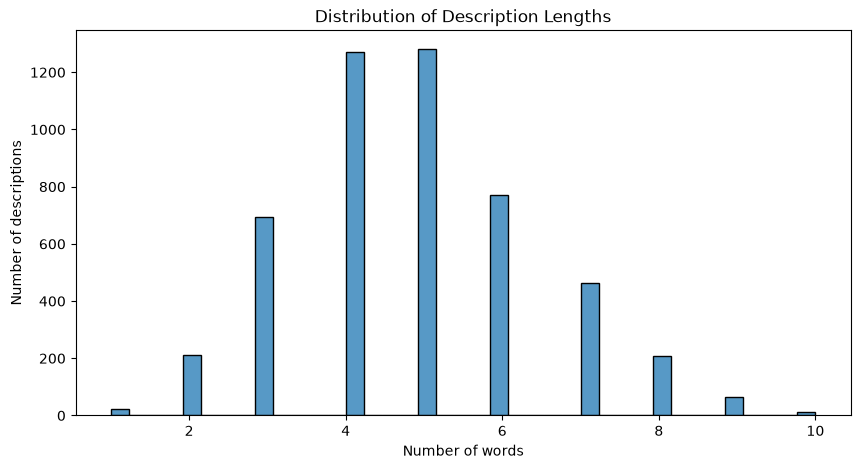

In [7]:
# - Analyze vocabulary and structure

# word count for each description
text_df["word_count"] = text_df["description"].fillna("").str.split().str.len()

print("Description Length Statistics:")
display(text_df["word_count"].describe())

# visualize description lengths
plt.figure(figsize=(10, 5))
sns.histplot(text_df["word_count"])
plt.title("Distribution of Description Lengths")
plt.xlabel("Number of words")
plt.ylabel("Number of descriptions")
plt.show()

In [8]:
# combine descriptions into one string
all_text = " ".join(text_df["description"].dropna()).lower()

# split text into individual words
words = all_text.split()

# count unique words
vocabulary = set(words)

print("Total Words:", len(words))
print("Unique Words:", len(vocabulary))

# find 20 most common words
word_counts = Counter(words)

print("\n20 most common words:")
display(pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Count"]
))

Total Words: 24270
Unique Words: 305

20 most common words:


,Word,Count
0,with,727
1,glass,424
2,empty,348
3,bottle,342
4,food,316
5,paper,316
6,box,313
7,residue,309
8,plastic,251
9,brand,247


Waste Category Distribution:


category
Vegetation             600
Textile Trash          586
Cardboard              584
Miscellaneous Trash    578
Plastic                569
Glass                  551
Food Organics          518
Metal                  508
Paper                  506
Name: count, dtype: int64

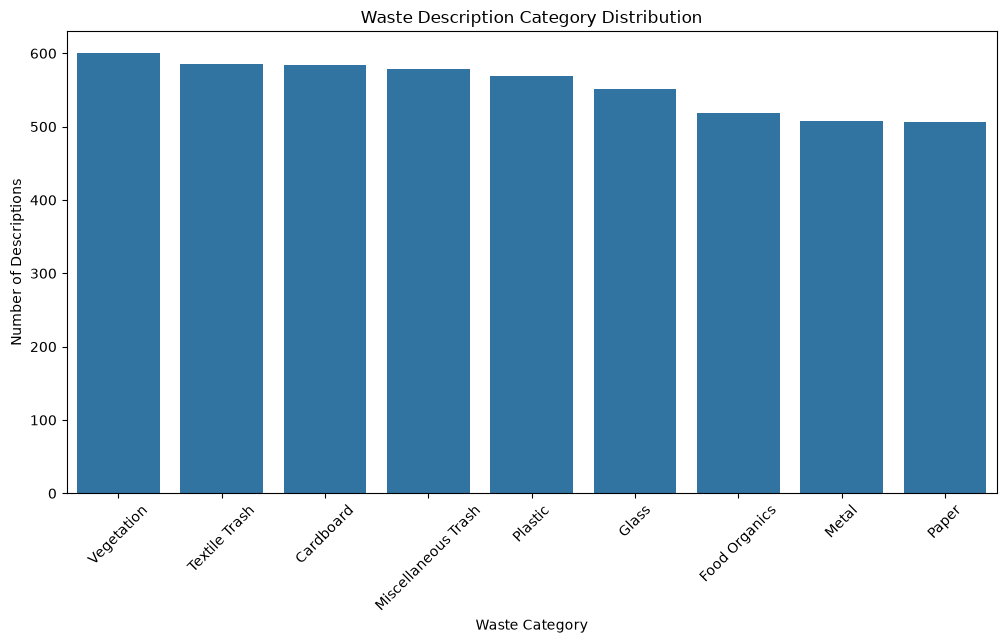

In [9]:
# - Understand the distribution of categories
# Count descriptions in each category
category_counts = text_df["category"].value_counts()

# Display category counts
print("Waste Category Distribution:")
display(category_counts)

# Plot category distribution
plt.figure(figsize=(12, 6))
sns.barplot(x=category_counts.index, y=category_counts.values)
plt.title("Waste Description Category Distribution")
plt.xlabel("Waste Category")
plt.ylabel("Number of Descriptions")
plt.xticks(rotation=45)
plt.show()

In [10]:
# TODO: Load and explore the waste policy documents
# - Load waste_policy_documents.csv
with open("waste_policy_documents.json", "r") as file:
    policies = json.load(file)

# convert to DF
policy_df = pd.DataFrame(policies)

# Display first 5 policies
policy_df.head()

,policy_id,policy_type,categories_covered,effective_date,document_text,jurisdiction
0,1,Textile Trash Recycling Guidelines,[Textile Trash],2023-11-04,TEXTILE RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
1,2,Glass Recycling Guidelines,[Glass],2023-01-24,GLASS RECYCLING GUIDELINES\n\nAcceptable Items...,Metro City
2,3,Food Organics Recycling Guidelines,[Food Organics],2023-05-08,FOOD ORGANICS RECYCLING GUIDELINES\n\nAcceptab...,Metro City
3,4,Plastic Recycling Guidelines,[Plastic],2023-04-05,PLASTIC RECYCLING GUIDELINES\n\nAcceptable Ite...,Metro City
4,5,Vegetation Recycling Guidelines,[Vegetation],2023-12-04,VEGETATION RECYCLING GUIDELINES\n\nAcceptable ...,Metro City


In [11]:
# - Understand document organization and language

# Document organization

print("\nColumn Names:")
print(policy_df.columns.tolist())

print("\nDataset Information:")
policy_df.info()

# Count policies by type
print("\nPolicy Types:")
display(policy_df["policy_type"].value_counts())

# Display categories covered
print("\nCategories Covered:")
display(policy_df["categories_covered"].explode().value_counts())

# Display jurisdictions
print("\nJurisdications:")
display(policy_df["jurisdiction"].explode().value_counts())


Column Names:
['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'document_text', 'jurisdiction']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   policy_id           14 non-null     int64 
 1   policy_type         14 non-null     str   
 2   categories_covered  14 non-null     object
 3   effective_date      14 non-null     str   
 4   document_text       14 non-null     str   
 5   jurisdiction        14 non-null     str   
dtypes: int64(1), object(1), str(4)
memory usage: 10.8+ KB

Policy Types:


policy_type
Textile Trash Recycling Guidelines          1
Glass Recycling Guidelines                  1
Food Organics Recycling Guidelines          1
Plastic Recycling Guidelines                1
Vegetation Recycling Guidelines             1
Cardboard Recycling Guidelines              1
Metal Recycling Guidelines                  1
Paper Recycling Guidelines                  1
Miscellaneous Trash Recycling Guidelines    1
Municipal Waste Guidelines                  1
Residential Recycling Rules                 1
Commercial Recycling Standards              1
Multi-Unit Building Guidelines              1
Community Recycling Program                 1
Name: count, dtype: int64


Categories Covered:


categories_covered
Vegetation             4
Metal                  4
Miscellaneous Trash    4
Textile Trash          3
Glass                  3
Plastic                3
Cardboard              3
Food Organics          2
Paper                  1
Name: count, dtype: int64


Jurisdications:


jurisdiction
Metro City    14
Name: count, dtype: int64

Policy Document Length Statistics:


count     14.000000
mean     101.785714
std       15.115853
min       86.000000
25%       94.250000
50%       99.000000
75%      102.000000
max      146.000000
Name: word_count, dtype: float64

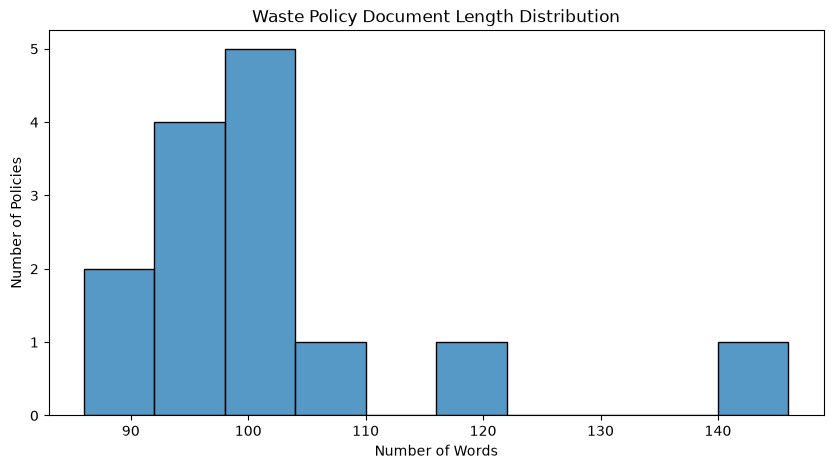

In [12]:
# Document language

# Calculate word count for each policy
policy_df["word_count"] = policy_df["document_text"].str.split().str.len()

# Display word count statistics
print("Policy Document Length Statistics:")
display(policy_df["word_count"].describe())

# Plot document lengths
plt.figure(figsize=(10, 5))
sns.histplot(policy_df["word_count"])
plt.title("Waste Policy Document Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Policies")
plt.show()

### 1.3 Create Data Pipelines

In [13]:
# Run this code to setup the images properly into train, validation, and test sets
# Set your data directory path - update this with your actual path
import pathlib
data_dir = pathlib.Path('./realwaste-main/RealWaste/')

# Parameters
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224

# Calculate the total number of classes automatically from the directory structure
num_classes = len([item for item in data_dir.glob('*') if item.is_dir()])
print(f"Number of classes: {num_classes}")

# List all class folders
class_names = sorted([item.name for item in data_dir.glob('*') if item.is_dir()])
print(f"Class names: {class_names}")

# Count all images
image_count = len(list(data_dir.glob('*/*.jpg'))) + len(list(data_dir.glob('*/*.png')))
print(f"Total images found: {image_count}")

# Create a dataset using tf.keras.utils.image_dataset_from_directory
# This will automatically split the data into training and validation sets
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="training",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.2,  # 20% for validation
    subset="validation",
    seed=42,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical',  # For one-hot encoded labels
    shuffle=True
)

# Create a separate test dataset by taking part of the validation set
# First, let's get the number of batches in the validation set
val_batches = tf.data.experimental.cardinality(validation_ds)
test_dataset = validation_ds.take(val_batches // 2)
validation_ds = validation_ds.skip(val_batches // 2)

print(f"Number of training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Number of validation batches: {tf.data.experimental.cardinality(validation_ds)}")
print(f"Number of test batches: {tf.data.experimental.cardinality(test_dataset)}")

# Configure dataset for performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Found 4752 files belonging to 9 classes.
Using 3802 files for training.
Found 4752 files belonging to 9 classes.
Using 950 files for validation.
Number of training batches: 119
Number of validation batches: 15
Number of test batches: 15


In [14]:
# TODO: Create a text preprocessing pipeline
# - Text cleaning

# Load text dataset if not already loaded
text_df = pd.read_csv("waste_descriptions.csv")

# Remove rows with missing descriptions or categories
text_df = text_df.dropna(subset=["description", "category"]).copy()

# Function to clean text
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", "", text)
    return text.strip()

# Apply cleaning
text_df["clean_description"] = text_df["description"].apply(clean_text)

# Display cleaned descriptions
display(text_df[["description", "clean_description"]].head())

,description,clean_description
0,soiled silver tablecloth,soiled silver tablecloth
1,folded glass bottle leaking,folded glass bottle leaking
2,large Supermarket vegetable waste with food re...,large supermarket vegetable waste with food re...
3,intact floral carpet piece,intact floral carpet piece
4,empty fun-sized purple apple core,empty funsized purple apple core


In [15]:
# Encode waste cetegories

# Convert category names to numerical labels
label_encoder = LabelEncoder()

text_df["label"] = label_encoder.fit_transform(text_df["category"])

# Display category mappings
for i, category in enumerate(label_encoder.classes_):
    print(f"{i}: {category}")

# Number of classes
num_text_classes = len(label_encoder.classes_)

0: Cardboard
1: Food Organics
2: Glass
3: Metal
4: Miscellaneous Trash
5: Paper
6: Plastic
7: Textile Trash
8: Vegetation


In [16]:
# - Split data into train and test
X = text_df["clean_description"]
y = text_df["label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4000
Testing samples: 1000


In [19]:
# - Tokenization

# Set vocabulary size and sequence length
MAX_TOKENS = 5000
MAX_LENGTH = 30

# Create text vectorization layer
vectorizer = TextVectorization(max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=MAX_LENGTH
)

# Learn vocabulary from training data only
vectorizer.adapt(X_train.to_numpy())

# Convert text into numerical sequences
X_train_seq = vectorizer(X_train.to_numpy())
X_test_seq = vectorizer(X_test.to_numpy())

print("Training Sequence Shape:", X_train_seq.shape)
print("Testing Sequence Shape:", X_test_seq.shape)

# Display an example
print("\nOriginal Description:")
print(X_train.iloc[0])

print("\nTokenized Sequence:")
print(X_train_seq[0].numpy())


Training Sequence Shape: (4000, 30)
Testing Sequence Shape: (1000, 30)

Original Description:
enormous pink flyer

Tokenized Sequence:
[ 24  59 266   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0]


In [20]:
# - Create embeddings/features
# Define embedding dimensions
EMBEDDING_DIM = 64

# Create embedding layer
embedding_layer = Embedding(
    input_dim=MAX_TOKENS,
    output_dim=EMBEDDING_DIM,
    mask_zero=True
)

# Generate embeddings for a sample
sample_embedding = embedding_layer(X_train_seq[:1])

print("Embedding Shape:", sample_embedding.shape)

Embedding Shape: (1, 30, 64)


In [21]:
# TODO: Prepare documents for RAG
# - Document preprocessing

# Handle missing values
policy_df["document_text"] = policy_df["document_text"].fillna("")
policy_df["policy_type"] = policy_df["policy_type"].fillna("")

# Combine relevant information into one text field
policy_df["processed_text"] = (
    policy_df["policy_type"] + ". " +
    policy_df["categories_covered"].apply(lambda x: ", ".join(x)) + ". " +
    policy_df["document_text"]
)

# Remove extra whitespace
policy_df["processed_text"] = (
    policy_df["processed_text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Display example
print(policy_df["processed_text"].iloc[0])

Textile Trash Recycling Guidelines. Textile Trash. TEXTILE RECYCLING GUIDELINES Acceptable Items: - Clean clothing (all conditions) - Towels, sheets, and linens - Fabric scraps - Curtains and cloth napkins - Handbags and backpacks made of fabric - Soft toys and stuffed animals Non-Acceptable Items: - Wet or moldy textiles - Heavily soiled items - Carpets and rugs - Footwear - Items with significant non-textile parts Collection Method: Place items in dedicated textile recycling bins or donate to local thrift stores. Preparation Instructions: - Ensure all items are clean and dry - Remove non-textile components when possible - Bag similar items together Benefits: Textile recycling conserves resources and reduces landfill waste.


In [22]:
# - Create embeddings for retrieval

# Load pretrained embedding model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

# Generate embeddings for policy documents
document_embeddings = embedding_model.encode(
    policy_df["processed_text"].tolist(),
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Document Embeddings Shape:", document_embeddings.shape)

/Users/mikeb/miniconda3/envs/bert_nlp/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Document Embeddings Shape: (14, 384)


## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [23]:
# TODO: Implement image preprocessing
# - Apply the preprocessing pipeline created earlier

# Normalize pixel values from 0-255 to 0-1
def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

# Apply normalization to all datasets
train_ds = train_ds.map(normalize_images)
validation_ds = validation_ds.map(normalize_images)
test_dataset = test_dataset.map(normalize_images)

# Check image shapes and pixel values
for images, labels in train_ds.take(1):
    print("Image Shape:", images.shape)
    print("Label Shape:", labels.shape)
    print("Minimum Pixel Value:", tf.reduce_min(images).numpy())
    print("Maximum Pixel Value:", tf.reduce_max(images).numpy())

Image Shape: (32, 224, 224, 3)
Label Shape: (32, 9)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


2026-10-23 14:09:29.236406: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.
2026-10-23 14:09:29.258057: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


2026-10-23 14:10:42.400701: W tensorflow/core/kernels/data/cache_dataset_ops.cc:858] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


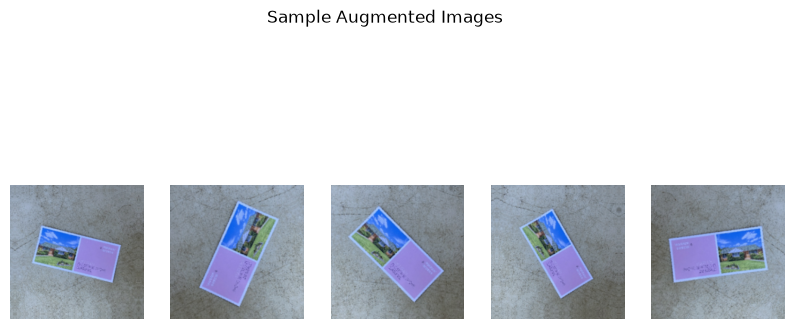

2026-10-23 14:10:42.613274: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [25]:
# Create image augmentation pipeline
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

# Display original and augmented images
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 5))

    for i in range(5):
        augmented_image = data_augmentation(
            images[0:1], training=True
        )
        plt.subplot(1, 5, i + 1)
        plt.imshow(augmented_image[0].numpy())
        plt.axis("off")

    plt.suptitle("Sample Augmented Images")
    plt.show()

### 2.2 Implement CNN Model with Transfer Learning

In [26]:
# TODO: Select an appropriate base model and implement transfer learning
# - Choose from MobileNet, EfficientNet, etc.
# - Add custom classification layers for the 9 waste categories
# - Configure loss function and metrics

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

In [27]:
# Build CNN model using transfer learning
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Image augmentation
    data_augmentation,

    # Convert normalized pixels from [0, 1] to [-1, 1]
    layers.Rescaling(2.0, offset=-1.0),

    # Pretrained MobileNetV2
    base_model,

    # Custom classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

# Display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [28]:
# Compile CNN model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [29]:
# Display model summary
model.summary()

# Check number of trainable parameters
print("Trainable Parameters:",
      sum(tf.size(w).numpy() for w in model.trainable_weights))

print("Number of Waste Categories:", num_classes)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,113 (9.24 MB)

 Trainable params: 165,129 (645.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Trainable Parameters: 165129
Number of Waste Categories: 9


### 2.3 Train and Evaluate the Model

In [30]:
# TODO: Train the CNN model
# - Use appropriate batch size and epochs
# - Implement regularization to prevent overfitting
# - Monitor training and validation metrics

# Configure training callbacks
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "best_waste_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

In [31]:
# Train CNN model
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


/Users/mikeb/miniconda3/envs/bert_nlp/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 68s 534ms/step - accuracy: 0.5768 - loss: 1.2167 - val_accuracy: 0.7106 - val_loss: 0.7844 - learning_rate: 0.0010
Epoch 2/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 65s 547ms/step - accuracy: 0.7278 - loss: 0.7565 - val_accuracy: 0.7511 - val_loss: 0.7065 - learning_rate: 0.0010
Epoch 3/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 64s 540ms/step - accuracy: 0.7812 - loss: 0.6363 - val_accuracy: 0.7660 - val_loss: 0.6702 - learning_rate: 0.0010
Epoch 4/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 66s 555ms/step - accuracy: 0.8035 - loss: 0.5452 - val_accuracy: 0.7830 - val_loss: 0.6272 - learning_rate: 0.0010
Epoch 5/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 62s 524ms/step - accuracy: 0.8214 - loss: 0.5047 - val_accuracy: 0.7872 - val_loss: 0.6295 - learning_rate: 0.0010
Epoch 6/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 65s 549ms/step - accuracy: 0.8459 - loss: 0.4347 - val_accuracy: 0.7936 - val_loss: 0.5937 - learning_rate: 0.0010
Epoch 7/20
119/119 ━━━━━━━━━━━━━━━━━━━━ 63s 530ms/step - accuracy: 0.8630 - loss:

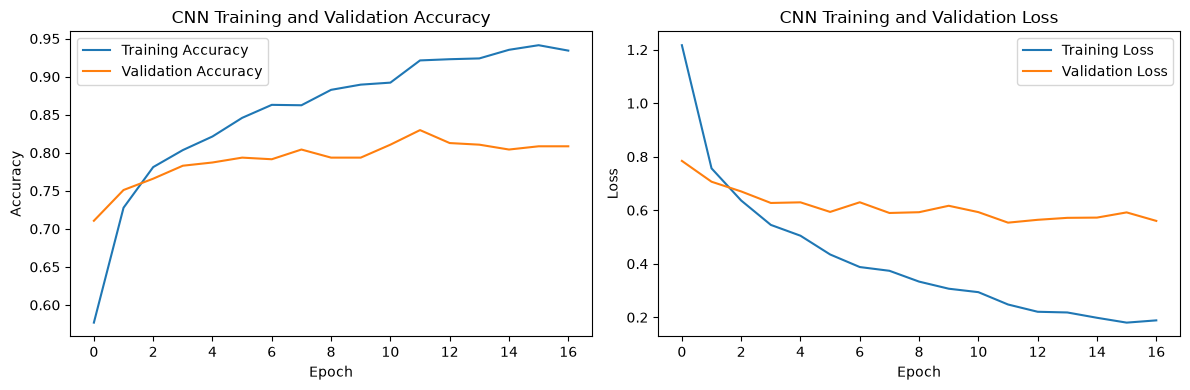

In [32]:
# Plot training and validation accuracy
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [33]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Evaluate model on test data
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 482ms/step - accuracy: 0.8583 - loss: 0.4685
Test Loss: 0.4685
Test Accuracy: 85.83%


In [34]:
# Get actual labels and model predictions
y_true = []
y_pred = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(predictions, axis=1))

# Convert to NumPy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total Test Images:", len(y_true))
print("Correct Predictions:", np.sum(y_true == y_pred))
print("Incorrect Predictions:", np.sum(y_true != y_pred))

Total Test Images: 480
Correct Predictions: 412
Incorrect Predictions: 68


2026-10-23 14:29:54.116073: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


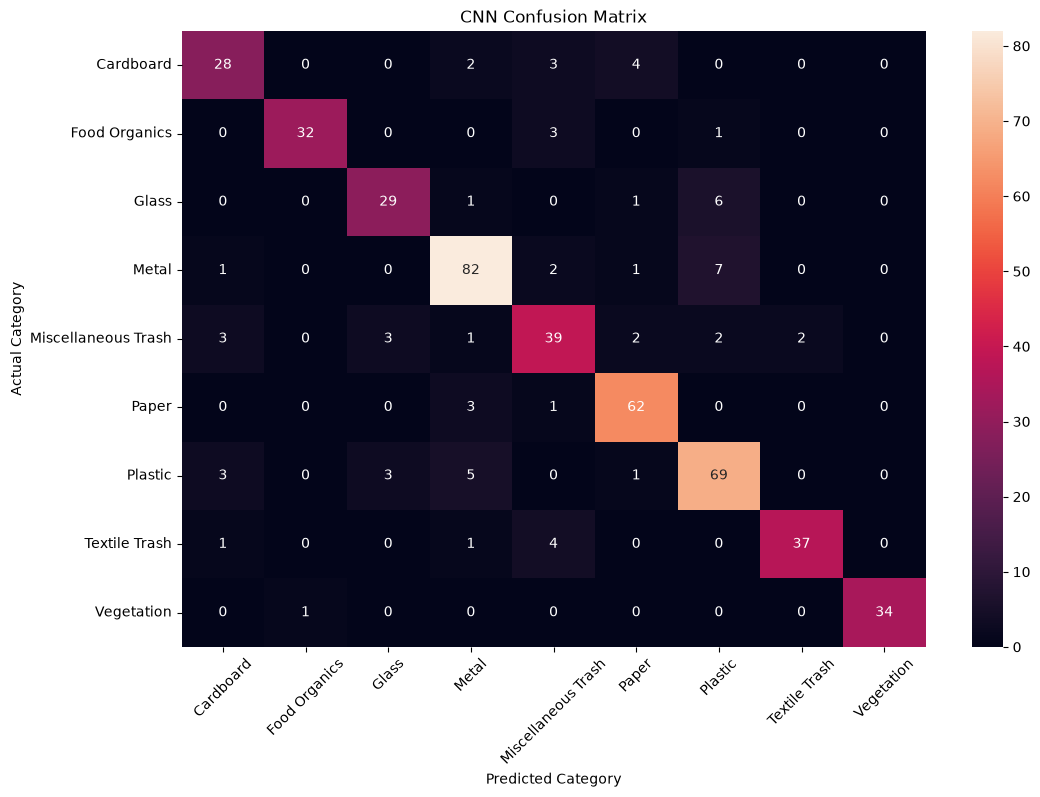

In [35]:
# Generate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))

# Plot confusion matrix
plt.figure(figsize=(12, 8))

sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [36]:
# Generate classification report
print("CNN Classification Report:")

print(classification_report(y_true, y_pred, labels=range(len(class_names)), target_names=class_names, zero_division=0))

# Calculate errors by category
errors = cm.sum(axis=1) - np.diag(cm)

error_df = pd.DataFrame({
    "Category": class_names,
    "Total Images": cm.sum(axis=1),
    "Incorrect Predictions": errors,
    "Error Rate (%)": np.divide(
        errors,
        cm.sum(axis=1),
        out=np.zeros(len(errors), dtype=float),
        where=cm.sum(axis=1) != 0
    ) * 100
})

# Sort by error rate
error_df = error_df.sort_values("Error Rate (%)", ascending=False)

print("\nClassification Errors by Category:")
display(error_df)

CNN Classification Report:
                     precision    recall  f1-score   support

          Cardboard       0.78      0.76      0.77        37
      Food Organics       0.97      0.89      0.93        36
              Glass       0.83      0.78      0.81        37
              Metal       0.86      0.88      0.87        93
Miscellaneous Trash       0.75      0.75      0.75        52
              Paper       0.87      0.94      0.91        66
            Plastic       0.81      0.85      0.83        81
      Textile Trash       0.95      0.86      0.90        43
         Vegetation       1.00      0.97      0.99        35

           accuracy                           0.86       480
          macro avg       0.87      0.85      0.86       480
       weighted avg       0.86      0.86      0.86       480


Classification Errors by Category:


,Category,Total Images,Incorrect Predictions,Error Rate (%)
4,Miscellaneous Trash,52,13,25.000000
0,Cardboard,37,9,24.324324
2,Glass,37,8,21.621622
6,Plastic,81,12,14.814815
7,Textile Trash,43,6,13.953488
3,Metal,93,11,11.827957
1,Food Organics,36,4,11.111111
5,Paper,66,4,6.060606
8,Vegetation,35,1,2.857143


### 2.4 Fine-tune the Model

In [37]:
# TODO: Tune model parameters to improve performance
# - Adjust learning rate
# - Add regularization, dropout
# - Modify architecture if needed

# Allow fine-tuning of MobileNetV2
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if layer.__class__.__name__ == "BatchNormalization":
        layer.trainable = False

# Verify that BatchNormalization layers are frozen
print("Trainable BatchNormalization layers:",
      sum(
          layer.trainable
          for layer in base_model.layers
          if layer.__class__.__name__ == "BatchNormalization"
      ))

Trainable BatchNormalization layers: 0


In [38]:
# Recompile CNN with a smaller learning rate for fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [39]:
# Fine-tune the model
fine_tune_history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10


/Users/mikeb/miniconda3/envs/bert_nlp/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 79s 617ms/step - accuracy: 0.9271 - loss: 0.2159 - val_accuracy: 0.8298 - val_loss: 0.5609 - learning_rate: 1.0000e-05
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 75s 626ms/step - accuracy: 0.9324 - loss: 0.1936 - val_accuracy: 0.8149 - val_loss: 0.5630 - learning_rate: 1.0000e-05
Epoch 3/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 79s 665ms/step - accuracy: 0.9316 - loss: 0.1917 - val_accuracy: 0.8128 - val_loss: 0.6137 - learning_rate: 1.0000e-05
Epoch 4/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 674ms/step - accuracy: 0.9461 - loss: 0.1603 - val_accuracy: 0.8234 - val_loss: 0.5679 - learning_rate: 1.0000e-05
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 79s 661ms/step - accuracy: 0.9500 - loss: 0.1525 - val_accuracy: 0.8277 - val_loss: 0.5691 - learning_rate: 5.0000e-06
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 81s 680ms/step - accuracy: 0.9495 - loss: 0.1414 - val_accuracy: 0.8255 - val_loss: 0.5559 - learning_rate: 5.0000e-06
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 80s 672ms/step - 

15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 524ms/step - accuracy: 0.8625 - loss: 0.4486
Original Test Accuracy: 85.83%
Tuned Test Accuracy: 86.25%
Accuracy Improvement: 0.42 percentage points


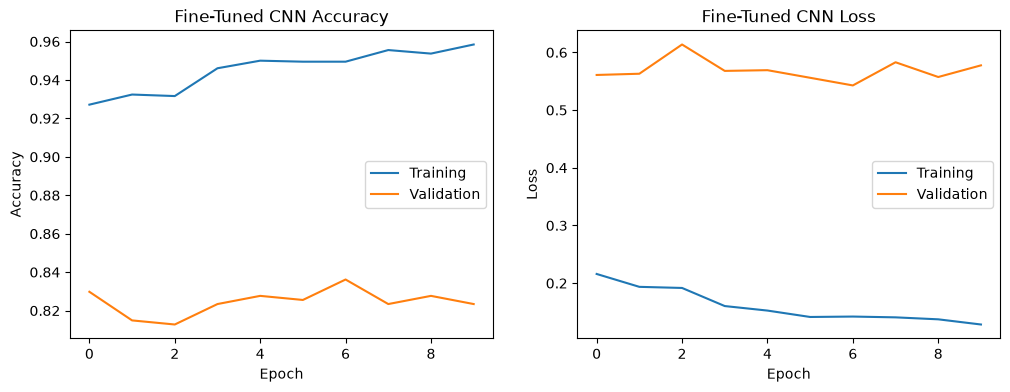

In [40]:
# Evaluate fine-tuned model
tuned_loss, tuned_accuracy = model.evaluate(test_dataset)

print(f"Original Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Tuned Test Accuracy: {tuned_accuracy * 100:.2f}%")
print(f"Accuracy Improvement: {(tuned_accuracy - test_accuracy) * 100:.2f} percentage points")

# Plot fine-tuning accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(fine_tune_history.history["accuracy"], label="Training")
plt.plot(fine_tune_history.history["val_accuracy"], label="Validation")
plt.title("Fine-Tuned CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(fine_tune_history.history["loss"], label="Training")
plt.plot(fine_tune_history.history["val_loss"], label="Validation")
plt.title("Fine-Tuned CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [41]:
# TODO: Implement text preprocessing
# - Apply the text preprocessing pipeline created earlier

# Convert descriptions into numerical sequences
X_train_seq = vectorizer(X_train.to_numpy())
X_test_seq = vectorizer(X_test.to_numpy())

# Convert labels to NumPy arrays
y_train_array = y_train.to_numpy()
y_test_array = y_test.to_numpy()

# Display dataset shapes
print("Training Features:", X_train_seq.shape)
print("Testing Features:", X_test_seq.shape)
print("Training Labels:", y_train_array.shape)
print("Testing Labels:", y_test_array.shape)

Training Features: (4000, 30)
Testing Features: (1000, 30)
Training Labels: (4000,)
Testing Labels: (1000,)


In [42]:
# Display an example description
print("Original Description:")
print(X_train.iloc[0])

print("\nTokenized Sequence:")
print(X_train_seq[0].numpy())

print("\nActual Category:")
print(label_encoder.inverse_transform([y_train_array[0]])[0])

print("\nNumber of Categories:", num_text_classes)

Original Description:
enormous pink flyer

Tokenized Sequence:
[ 24  59 266   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0]

Actual Category:
Paper

Number of Categories: 9


### 3.2 Implement Text Classification Model

In [43]:
# TODO: Choose and implement a text classification model
# Option A: Traditional ML model (Naive Bayes, Random Forest, etc.)
# Option B: Fine-tune a transformer-based model (BERT, DistilBERT, etc.)

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert text into numerical features
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# Display feature shapes
print("Training Features:", X_train_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)

Training Features: (4000, 303)
Testing Features: (1000, 303)


In [44]:
# Create Naive Bayes model
text_model = MultinomialNB()

# Train model
text_model.fit(X_train_tfidf, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](9,)","[467.,414.,441.,...,455.,469.,480.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](9,)","[-2.15,-2.27,-2.21,...,-2.17,-2.14,-2.12]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](9,)","[0,1,2,...,6,7,8]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](9, 303)","[[ 0. , 0. , 0. ,..., 0. , 7.21, 0. ], [ 0. , 0. , 8.66,..., 0. , 4.05, 0. ], [ 0. , 0. , 0. ,..., 0. , 6.39, 0. ], ..., [ 0. , 0. , 0. ,..., 0. , 9.66,12.31], [ 0. , 0. , 0. ,..., 0. , 3.87, 0. ], [ 0. , 0. , 0. ,...,13.64, 5.51, 0. ]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](9, 303)","[[-7.18,-7.18,-7.18,...,-7.18,-5.07,-7.18], [-7.08,-7.08,-4.81,...,-7.08,-5.46,-7.08], [-7.13,-7.13,-7.13,...,-7.13,-5.13,-7.13], ..., [-7.15,-7.15,-7.15,...,-7.15,-4.78,-4.56], [-7.18,-7.18,-7.18,...,-7.18,-5.6 ,-7.18], [-7.18,-7.18,-7.18,...,-4.5 ,-5.31,-7.18]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,303


In [45]:
# Predict waste categories
y_pred_text = text_model.predict(X_test_tfidf)

# Display sample predictions
results_df = pd.DataFrame({
    "Description": X_test.values,
    "Actual": label_encoder.inverse_transform(y_test.values),
    "Predicted": label_encoder.inverse_transform(y_pred_text)
})

display(results_df.head(10))

,Description,Actual,Predicted
0,partial travelsized gold brand b glass tabletop,Glass,Glass
1,oversized gold silicone imported leather belt,Textile Trash,Textile Trash
2,ripped standard blue natural plant stems,Vegetation,Vegetation
3,mini transparent natural appliance box,Cardboard,Cardboard
4,dry sixpack holder,Cardboard,Cardboard
5,partial receipt,Paper,Paper
6,small yellow moving box,Cardboard,Cardboard
7,dirty industrial orange houseplant,Vegetation,Vegetation
8,dirty oversized blue commercial water bottle w...,Plastic,Plastic
9,dirty compact white champagne bottle,Glass,Glass


In [46]:
# Test a new waste description
# new_description = ["empty plastic water bottle"]
new_description = ["toy apple playset"]

# Apply the same text cleaning
cleaned_text = [clean_text(text) for text in new_description]

# Convert to TF-IDF features
new_features = tfidf.transform(cleaned_text)

# Predict category
prediction = text_model.predict(new_features)

# Convert prediction to category name
predicted_category = label_encoder.inverse_transform(prediction)

print("Description:", new_description[0])
print("Predicted Category:", predicted_category[0])

Description: toy apple playset
Predicted Category: Plastic


### 3.3 Train and Evaluate the Model

In [47]:
# TODO: Train the text classification model
# - Use appropriate training parameters
# - Monitor training progress

# Calculate training accuracy
train_predictions = text_model.predict(X_train_tfidf)
train_accuracy = accuracy_score(y_train, train_predictions)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")

Training Accuracy: 99.50%


In [48]:
# TODO: Evaluate model performance
# - Calculate accuracy on test set
# - Generate confusion matrix
# - Analyze error patterns

# Predict categories using the test data
y_pred_text = text_model.predict(X_test_tfidf)

# Calculate test accuracy
test_accuracy_text = accuracy_score(y_test, y_pred_text)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Test Accuracy: {test_accuracy_text * 100:.2f}%")

Training Accuracy: 99.50%
Test Accuracy: 99.60%


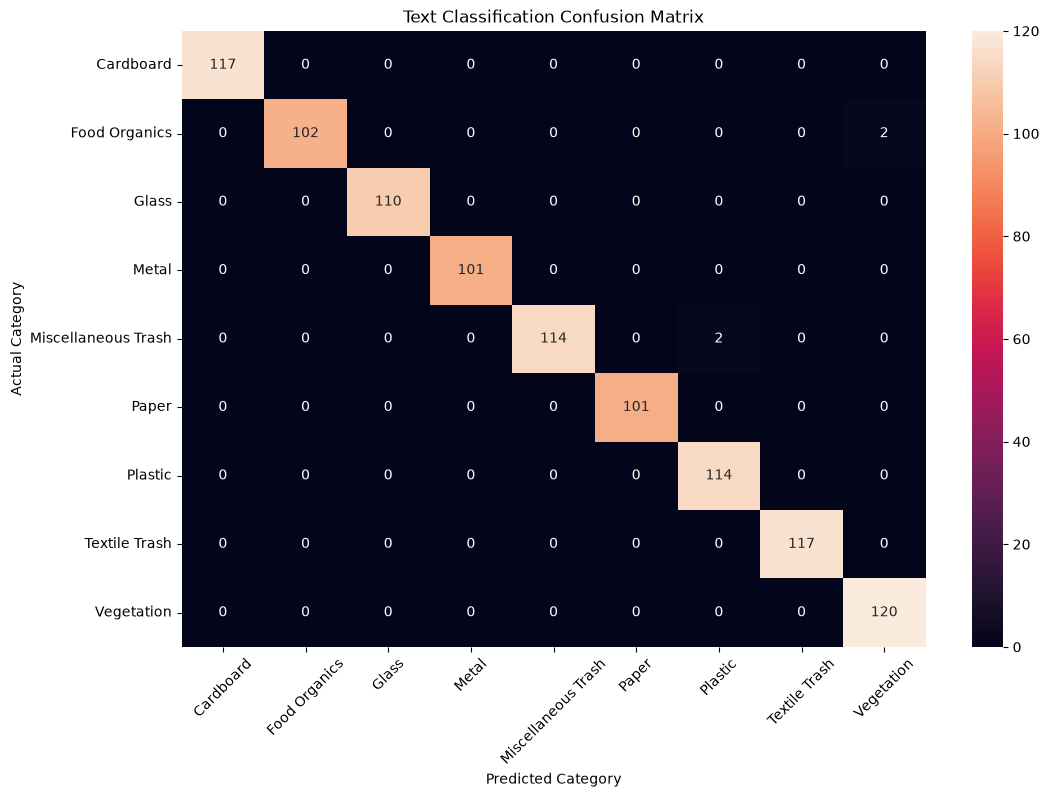

In [49]:
# Generate confusion matrix
cm_text = confusion_matrix(y_test, y_pred_text, labels=range(len(label_encoder.classes_)))

# Plot confusion matrix
plt.figure(figsize=(12, 8))

sns.heatmap(cm_text, annot=True, fmt="d", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)

plt.title("Text Classification Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

In [50]:
# Generate classification report
print("Text Classification Report:")

print(classification_report(
    y_test,
    y_pred_text,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

Text Classification Report:
                     precision    recall  f1-score   support

          Cardboard       1.00      1.00      1.00       117
      Food Organics       1.00      0.98      0.99       104
              Glass       1.00      1.00      1.00       110
              Metal       1.00      1.00      1.00       101
Miscellaneous Trash       1.00      0.98      0.99       116
              Paper       1.00      1.00      1.00       101
            Plastic       0.98      1.00      0.99       114
      Textile Trash       1.00      1.00      1.00       117
         Vegetation       0.98      1.00      0.99       120

           accuracy                           1.00      1000
          macro avg       1.00      1.00      1.00      1000
       weighted avg       1.00      1.00      1.00      1000



In [51]:
# Calculate errors for each category
errors = cm_text.sum(axis=1) - np.diag(cm_text)

# Create error analysis DataFrame
error_df_text = pd.DataFrame({
    "Category": label_encoder.classes_,
    "Total Descriptions": cm_text.sum(axis=1),
    "Incorrect Predictions": errors
})

# Calculate error rate
error_df_text["Error Rate (%)"] = (
    error_df_text["Incorrect Predictions"] /
    error_df_text["Total Descriptions"].replace(0, np.nan) * 100
).fillna(0).round(2)

# Sort by highest error rate
error_df_text = error_df_text.sort_values("Error Rate (%)", ascending=False)

print("Classification Errors by Category:")
display(error_df_text)

Classification Errors by Category:


,Category,Total Descriptions,Incorrect Predictions,Error Rate (%)
1,Food Organics,104,2,1.92
4,Miscellaneous Trash,116,2,1.72
0,Cardboard,117,0,0.00
2,Glass,110,0,0.00
3,Metal,101,0,0.00
5,Paper,101,0,0.00
6,Plastic,114,0,0.00
7,Textile Trash,117,0,0.00
8,Vegetation,120,0,0.00


In [52]:
# Create DataFrame of predictions
results_df = pd.DataFrame({
    "Description": X_test.values,
    "Actual": label_encoder.inverse_transform(y_test.to_numpy()),
    "Predicted": label_encoder.inverse_transform(y_pred_text)
})

# Filter incorrect predictions
incorrect_df = results_df[
    results_df["Actual"] != results_df["Predicted"]
]

print("Total Incorrect Predictions:", len(incorrect_df))

display(incorrect_df.head(20))

Total Incorrect Predictions: 4


,Description,Actual,Predicted
402,compact striped vegetable waste with food residue,Food Organics,Vegetation
691,patterned supermarket vegetable waste sealed,Food Organics,Vegetation
880,broken mini ecofriendly toy,Miscellaneous Trash,Plastic
889,green homemade toy with contents,Miscellaneous Trash,Plastic


### 3.4 Create Classification Function

In [53]:
# TODO: Create a function that takes a text description and returns the predicted waste category

def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    # Your code here
    
    # Clean the description
    cleaned_text = clean_text(description)

    # Convert text into TF-IDF features
    features = tfidf.transform([cleaned_text])

    # Predict waste category
    prediction = text_model.predict(features)

    # Convert numerical prediction to category name
    category = label_encoder.inverse_transform(prediction)[0]

    return category

## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [54]:
# TODO: Prepare documents for retrieval
# - Process policy documents and disposal instructions
# - Create embeddings for efficient retrieval

# Prepare policy documents for retrieval
policy_docs = policy_df.copy()

# Combine policy information into searchable text
policy_docs["search_text"] = (
    policy_docs["policy_type"] + ". " +
    policy_docs["categories_covered"].apply(
        lambda x: ", ".join(x)
    ) + ". " +
    policy_docs["document_text"]
)

# Display sample
display(policy_docs[["policy_type", "search_text"]].head())

,policy_type,search_text
0,Textile Trash Recycling Guidelines,Textile Trash Recycling Guidelines. Textile Tr...
1,Glass Recycling Guidelines,Glass Recycling Guidelines. Glass. GLASS RECYC...
2,Food Organics Recycling Guidelines,Food Organics Recycling Guidelines. Food Organ...
3,Plastic Recycling Guidelines,Plastic Recycling Guidelines. Plastic. PLASTIC...
4,Vegetation Recycling Guidelines,Vegetation Recycling Guidelines. Vegetation. V...


In [55]:
# Prepare disposal instructions
disposal_docs = text_df.copy()

# Remove rows with missing instructions
disposal_docs = disposal_docs.dropna(
    subset=["description", "category", "disposal_instruction"]
)

# Combine descriptions, categories, and instructions
disposal_docs["search_text"] = (
    disposal_docs["category"] + ". " +
    disposal_docs["description"] + ". " +
    disposal_docs["disposal_instruction"]
)

# Display sample
display(disposal_docs[["category", "search_text"]].head())

,category,search_text
0,Textile Trash,Textile Trash. soiled silver tablecloth. Look ...
1,Glass,Glass. folded glass bottle leaking. Remove cap...
2,Food Organics,Food Organics. large Supermarket vegetable was...
3,Textile Trash,Textile Trash. intact floral carpet piece. Loo...
4,Food Organics,Food Organics. empty fun-sized purple apple co...


In [56]:
# Create a combined document collection
policy_records = pd.DataFrame({
    "source": "Policy",
    "category": policy_docs["categories_covered"].apply(
        lambda x: ", ".join(x)
    ),
    "text": policy_docs["search_text"]
})

disposal_records = pd.DataFrame({
    "source": "Disposal Instruction",
    "category": disposal_docs["category"],
    "text": disposal_docs["search_text"]
})

# Combine both sources
rag_documents = pd.concat(
    [policy_records, disposal_records],
    ignore_index=True
)

print("Total RAG Documents:", len(rag_documents))

print("\nDocuments by Source:")
print(rag_documents["source"].value_counts())

display(rag_documents.head())

Total RAG Documents: 5014

Documents by Source:
source
Disposal Instruction    5000
Policy                    14
Name: count, dtype: int64


,source,category,text
0,Policy,Textile Trash,Textile Trash Recycling Guidelines. Textile Tr...
1,Policy,Glass,Glass Recycling Guidelines. Glass. GLASS RECYC...
2,Policy,Food Organics,Food Organics Recycling Guidelines. Food Organ...
3,Policy,Plastic,Plastic Recycling Guidelines. Plastic. PLASTIC...
4,Policy,Vegetation,Vegetation Recycling Guidelines. Vegetation. V...


In [57]:
# Generate embeddings for all RAG documents
rag_embeddings = embedding_model.encode(
    rag_documents["text"].tolist(),
    show_progress_bar=True,
    normalize_embeddings=True
)

print("Total Documents:", len(rag_documents))
print("Embedding Shape:", rag_embeddings.shape)

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Total Documents: 5014
Embedding Shape: (5014, 384)


### 4.2 Implement RAG-based System

In [58]:
# TODO: Select a pre-trained language model and implement RAG
# - Choose an appropriate language model
# - Create a retrieval mechanism

# Retrieve relevant documents using semantic similarity

def retrieve_documents(query, top_k=3, min_similarity=0.30, source=None):

    # Convert query into an embedding
    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True
    )

    # Calculate similarity against document embeddings
    similarities = cosine_similarity(
        query_embedding,
        rag_embeddings
    )[0]

    # Copy documents and attach similarity scores
    results = rag_documents.copy()
    results["similarity"] = similarities

    # Optionally filter by document source
    if source is not None:
        results = results[results["source"] == source]

    # Select most relevant documents above threshold
    results = results[
        results["similarity"] >= min_similarity
    ]

    results = results.sort_values(
        "similarity",
        ascending=False
    ).head(top_k)

    return results

In [59]:
# Load pretrained text generation model
generator = pipeline(
    "text2text-generation",
    model="google/flan-t5-small"
)

/Users/mikeb/miniconda3/envs/bert_nlp/lib/python3.11/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Hardware accelerator e.g. GPU is available in the environment, but no `device` argument is passed to the `Pipeline` object. Model will be on CPU.


### 4.3 Adjust and Evaluate the System

In [60]:
# TODO: Train the RAG-based system
# - Adjust sampling methods/parameters

# RAG retrieval parameters
TOP_K = 3
MIN_SIMILARITY = 0.30

# Text generation parameter
MAX_NEW_TOKENS = 100

print("RAG Parameters:")
print("Top K:", TOP_K)
print("Minimum Similarity:", MIN_SIMILARITY)
print("Max New Tokens:", MAX_NEW_TOKENS)

RAG Parameters:
Top K: 3
Minimum Similarity: 0.3
Max New Tokens: 100


In [61]:
# Example waste description
query = "How should I recycle a glass bottle?"

# Test retrieval
results = retrieve_documents(
    query,
    top_k=TOP_K,
    min_similarity=MIN_SIMILARITY
)

# Display results
display(results[["source", "category", "similarity", "text"]])

,source,category,similarity,text
875,Disposal Instruction,Glass,0.805179,Glass. clean massive Bulk glass bottle. Rinse ...
34,Disposal Instruction,Glass,0.765695,Glass. clean red wine bottle with food residue...
1917,Disposal Instruction,Glass,0.758799,Glass. dirty small yellow wine bottle. Rinse c...


In [62]:
# Generate recycling instructions from a waste description

def generate_instructions_from_description(description):

    # Retrieve policy documents
    documents = retrieve_documents(
        description,
        top_k=TOP_K,
        min_similarity=MIN_SIMILARITY,
        source="Policy"
    )

    if documents.empty:
        return "No relevant recycling policy found."

    # Combine policy documents into context
    context = "\n".join(documents["text"].tolist())

    # Create a simple, direct prompt
    prompt = f"""
Answer using only the recycling policy below.

Policy:
{context[:1500]}

Question: How should I dispose of {description}?

Give one or two clear sentences.
If the policy does not provide enough information, say so.

Answer:
"""

    # Generate a deterministic response
    response = generator(
        prompt,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False
    )

    return response[0]["generated_text"]

In [63]:
# Sample test cases
test_cases = {
    "empty glass bottle": "Glass",
    "old cotton shirt": "Textile Trash",
    "plastic water bottle": "Plastic",
    "banana peel": "Food Organics"
}

correct = 0

for description, expected_category in test_cases.items():

    documents = retrieve_documents(description, top_k=3)

    retrieved_categories = documents["category"].tolist()

    # Check whether the expected category was retrieved
    match = any(
        expected_category in category.split(", ")
        for category in retrieved_categories
    )

    correct += int(match)

    print(f"{description}: {'Correct' if match else 'Incorrect'}")

retrieval_accuracy = correct / len(test_cases)

print(f"\nRetrieval Accuracy: {retrieval_accuracy * 100:.2f}%")

empty glass bottle: Correct
old cotton shirt: Correct
plastic water bottle: Correct
banana peel: Correct

Retrieval Accuracy: 100.00%


In [64]:
# Evaluate generated instructions across waste categories

test_items = {
    "Glass": "empty glass bottle",
    "Plastic": "plastic water bottle",
    "Paper": "old newspaper",
    "Cardboard": "cardboard shipping box",
    "Metal": "empty aluminum soda can",
    "Food Organics": "banana peel",
    "Textile Trash": "old cotton shirt",
    "Vegetation": "fallen tree leaves",
    "Miscellaneous Trash": "broken ceramic plate"
}

# Generate instructions for each category
evaluation_results = []

for expected_category, description in test_items.items():

    instructions = generate_instructions_from_description(
        description
    )

    evaluation_results.append({
        "Waste Category": expected_category,
        "Description": description,
        "Generated Instructions": instructions
    })

# Convert results to DataFrame
rag_eval_df = pd.DataFrame(evaluation_results)

display(rag_eval_df)

,Waste Category,Description,Generated Instructions
0,Glass,empty glass bottle,Place in dedicated glass recycling bins. Some ...
1,Plastic,plastic water bottle,Plastic water bottle is a waste product.
2,Paper,old newspaper,No relevant recycling policy found.
3,Cardboard,cardboard shipping box,Place recyclables in appropriate bins.
4,Metal,empty aluminum soda can,Place recyclables in appropriate bins.
5,Food Organics,banana peel,No relevant recycling policy found.
6,Textile Trash,old cotton shirt,"Towels, sheets, and linens are acceptable."
7,Vegetation,fallen tree leaves,No relevant recycling policy found.
8,Miscellaneous Trash,broken ceramic plate,No relevant recycling policy found.


In [65]:
relevance_scores = []

for _, row in rag_eval_df.iterrows():

    embeddings = embedding_model.encode([
        row["Description"],
        row["Generated Instructions"]
    ])

    similarity = cosine_similarity(
        [embeddings[0]],
        [embeddings[1]]
    )[0][0]

    relevance_scores.append(similarity)

rag_eval_df["Relevance Score"] = relevance_scores

display(rag_eval_df[[
    "Waste Category",
    "Description",
    "Relevance Score"
]])

,Waste Category,Description,Relevance Score
0,Glass,empty glass bottle,0.414507
1,Plastic,plastic water bottle,0.774398
2,Paper,old newspaper,0.156725
3,Cardboard,cardboard shipping box,0.276632
4,Metal,empty aluminum soda can,0.319954
5,Food Organics,banana peel,0.097097
6,Textile Trash,old cotton shirt,0.328245
7,Vegetation,fallen tree leaves,-0.036127
8,Miscellaneous Trash,broken ceramic plate,0.042389


In [66]:
# Review generated recycling instructions against policies

for index, row in rag_eval_df.iterrows():

    print("=" * 70)
    print(f"Category: {row['Waste Category']}")
    print(f"Description: {row['Description']}")

    print("\nGENERATED INSTRUCTIONS:")
    print(row["Generated Instructions"])

    print("\nRELEVANT POLICY DOCUMENTS:")

    documents = retrieve_documents(
        row["Description"],
        top_k=3,
        min_similarity=MIN_SIMILARITY,
        source="Policy"
    )

    if documents.empty:
        print("No sufficiently similar policy documents found.")
    else:
        for _, doc in documents.iterrows():
            print(f"\nSimilarity: {doc['similarity']:.3f}")
            print(doc["text"])

    print()

Category: Glass
Description: empty glass bottle

GENERATED INSTRUCTIONS:
Place in dedicated glass recycling bins. Some areas require color sorting. Preparation Instructions: - Rinse containers

RELEVANT POLICY DOCUMENTS:

Similarity: 0.426
Glass Recycling Guidelines. Glass. GLASS RECYCLING GUIDELINES

Acceptable Items:
- Glass bottles (all colors)
- Glass jars
- Glass food containers
- Glass beverage containers

Non-Acceptable Items:
- Window glass or mirrors
- Drinking glasses
- Ceramics or pottery
- Light bulbs
- Pyrex or heat-resistant glass

Collection Method:
Place in dedicated glass recycling bins. Some areas require color sorting.

Preparation Instructions:
- Rinse containers
- Remove caps and lids (recycle separately)
- Labels can remain

Benefits:
Glass is 100% recyclable and can be recycled endlessly without loss of quality.

Category: Plastic
Description: plastic water bottle

GENERATED INSTRUCTIONS:
Plastic water bottle is a waste product.

RELEVANT POLICY DOCUMENTS:

Simil

In [67]:
# Manual RAG accuracy scores
# 1.0 = Correct
# 0.5 = Partially correct
# 0.0 = Incorrect
# np.nan = Not reviewed

accuracy_scores = {
    "Glass": 1.0,
    "Plastic": 0.5,
    "Paper": 0.0,
    "Cardboard": 1.0,
    "Metal": 1.0,
    "Food Organics": 0.0,
    "Textile Trash": 1.0,
    "Vegetation": 0.0,
    "Miscellaneous Trash": 0.0
}

# Add manual scores to evaluation results
rag_eval_df["Accuracy Score"] = (
    rag_eval_df["Waste Category"].map(accuracy_scores)
)

display(rag_eval_df[[
    "Waste Category",
    "Relevance Score",
    "Accuracy Score"
]])

,Waste Category,Relevance Score,Accuracy Score
0,Glass,0.414507,1.0
1,Plastic,0.774398,0.5
2,Paper,0.156725,0.0
3,Cardboard,0.276632,1.0
4,Metal,0.319954,1.0
5,Food Organics,0.097097,0.0
6,Textile Trash,0.328245,1.0
7,Vegetation,-0.036127,0.0
8,Miscellaneous Trash,0.042389,0.0


In [68]:
# Summarize RAG evaluation results

print("RAG Evaluation Summary")
print("-" * 40)

print(f"Total Test Cases: {len(rag_eval_df)}")

# Average relevance score
average_relevance = rag_eval_df["Relevance Score"].mean()

print(f"Average Relevance Score: {average_relevance:.3f}")

# Average manual accuracy score
reviewed_scores = rag_eval_df["Accuracy Score"].dropna()

if len(reviewed_scores) > 0:
    print(f"Average Accuracy Score: {reviewed_scores.mean():.2f}")
    print(f"Instructions Reviewed: {len(reviewed_scores)}")
else:
    print("Manual accuracy review not yet completed.")

RAG Evaluation Summary
----------------------------------------
Total Test Cases: 9
Average Relevance Score: 0.264
Average Accuracy Score: 0.50
Instructions Reviewed: 9


### 4.4 Create Instruction Generation Function

In [69]:
# TODO: Create a function that takes a waste category and generates recycling instructions

def generate_recycling_instructions(waste_category):

    # Retrieve policy documents for the category
    documents = retrieve_documents(
        waste_category,
        top_k=TOP_K,
        min_similarity=MIN_SIMILARITY,
        source="Policy"
    )

    if documents.empty:
        return "No relevant recycling policy found.", []

    # Collect relevant policies
    relevant_policies = documents["text"].tolist()

    context = "\n".join(relevant_policies)

    # Create prompt
    prompt = f"""
Answer using only the recycling policy below.

Policy:
{context[:1500]}

Question: How should I dispose of {waste_category} waste?

Give one or two clear sentences.
If the policy does not provide enough information, say so.

Answer:
"""

    # Generate instructions
    response = generator(
        prompt,
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=False
    )

    instructions = response[0]["generated_text"]

    return instructions, relevant_policies

In [70]:
# Test recycling instruction generation
waste_category = "Plastic"

instructions, policies = generate_recycling_instructions(
    waste_category
)

print("Waste Category:", waste_category)

print("\nGenerated Recycling Instructions:")
print(instructions)

print("\nRelevant Policy Documents:")

for i, policy in enumerate(policies, start=1):
    print(f"\nPolicy {i}:")
    print(policy)

Waste Category: Plastic

Generated Recycling Instructions:
Place recyclables in appropriate bins.

Relevant Policy Documents:

Policy 1:
Residential Recycling Rules. Plastic, Metal, Glass, Miscellaneous Trash, Vegetation. RESIDENTIAL RECYCLING RULES

GENERAL REQUIREMENTS:
- Place recyclables in appropriate bins
- Ensure materials are clean and properly sorted
- Follow collection schedules
- Keep hazardous materials separate


PLASTIC GUIDELINES:
- PET bottles and containers (code #1)
- HDPE containers (code #2)
- PP containers (code #5)
- Clean plastic packaging
- Plastic bags and film

METAL GUIDELINES:
- Aluminum cans
- Steel food cans
- Metal lids and bottle caps
- Clean aluminum foil
- Empty aerosol cans

GLASS GUIDELINES:
- Glass bottles (all colors)
- Glass jars
- Glass food containers
- Glass beverage containers
- Window glass or mirrors

MISCELLANEOUS TRASH GUIDELINES:
- Multi-material items
- Heavily soiled packaging
- Certain plastic types (check local guidelines)
- Broken ho

## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

In [71]:
# TODO: Design an architecture that integrates all three models
# - Create interfaces between components
# - Handle input/output flow

def classify_waste_image(image_path):
    """
    Classifies a waste image using the trained CNN.

    Args:
        image_path (str): Path to waste image

    Returns:
        str: Predicted waste category
    """

    # Load and resize image
    image = load_img(
        image_path,
        target_size=(IMG_HEIGHT, IMG_WIDTH)
    )

    # Convert image to array
    image_array = img_to_array(image)

    # Normalize pixel values
    image_array = image_array / 255.0

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Predict category
    prediction = model.predict(image_array, verbose=0)

    # Get predicted category
    predicted_index = np.argmax(prediction[0])
    category = class_names[predicted_index]

    return category

### 5.2 Implement Integrated Assistant

In [72]:
# TODO: Implement the integrated waste management assistant

def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions
    """
    # Your code here
    # Step 1: Classify input
    if input_type == "image":

        # Load image from file path or array
        if isinstance(input_data, (str, bytes)):
            image = load_img(
                input_data,
                target_size=(IMG_HEIGHT, IMG_WIDTH)
            )
            image_array = img_to_array(image)

        else:
            image_array = np.asarray(input_data)
            image_array = tf.image.resize(
                image_array,
                (IMG_HEIGHT, IMG_WIDTH)
            ).numpy()

        # Normalize image if pixel values are 0-255
        image_array = image_array.astype("float32")

        if image_array.max() > 1.0:
            image_array = image_array / 255.0

        # Add batch dimension
        image_array = np.expand_dims(image_array, axis=0)

        # Predict waste category
        prediction = model.predict(image_array, verbose=0)[0]

        predicted_index = np.argmax(prediction)

        category = class_names[predicted_index]
        confidence = float(prediction[predicted_index])

    elif input_type == "text":

        # Clean text description
        cleaned_text = clean_text(input_data)

        # Convert text to TF-IDF features
        features = tfidf.transform([cleaned_text])

        # Predict waste category probabilities
        probabilities = text_model.predict_proba(features)[0]

        predicted_index = np.argmax(probabilities)

        # Convert predicted label to category name
        predicted_label = text_model.classes_[predicted_index]

        category = label_encoder.inverse_transform(
            [predicted_label]
        )[0]

        confidence = float(probabilities[predicted_index])

    else:
        raise ValueError("input_type must be 'image' or 'text'")

    # Step 2: Generate recycling instructions using RAG
    instructions, policies = generate_recycling_instructions(
        category
    )

    # Step 3: Return combined results
    result = {
        "input_type": input_type,
        "waste_category": category,
        "confidence": round(confidence, 4),
        "recycling_instructions": instructions,
        "relevant_policies": policies
    }

    return result

In [73]:
# Test using a waste description
result = waste_management_assistant(
    "empty plastic water bottle",
    input_type="text"
)

print("Predicted Category:", result["waste_category"])
print("Confidence:", result["confidence"])
print("Recycling Instructions:", result["recycling_instructions"])

Predicted Category: Plastic
Confidence: 0.928
Recycling Instructions: Place recyclables in appropriate bins.


In [74]:
# Test using a waste image
result = waste_management_assistant(
    image_path,
    input_type="image"
)

print("Predicted Category:", result["waste_category"])
print("Confidence:", result["confidence"])
print("Recycling Instructions:", result["recycling_instructions"])

Predicted Category: Plastic
Confidence: 0.9962
Recycling Instructions: Place recyclables in appropriate bins.


### 5.3 Evaluate the Integrated System

In [75]:
# TODO: Evaluate the integrated system on test cases
# - Test with images from test dataset
# - Test with text descriptions from test dataset
# - Assess overall performance

# Evaluate integrated assistant using test images

image_results = []

# Select one batch of test images
for images, labels in test_dataset.take(1):

    # Test the first 10 images
    for i in range(min(10, len(images))):

        image = images[i].numpy()

        # Get actual category
        actual_index = np.argmax(labels[i].numpy())
        actual_category = class_names[actual_index]

        # Run integrated assistant
        result = waste_management_assistant(
            image,
            input_type="image"
        )

        # Store results
        image_results.append({
            "Actual": actual_category,
            "Predicted": result["waste_category"],
            "Confidence": result["confidence"],
            "Instructions": result["recycling_instructions"]
        })

# Convert results to DataFrame
image_results_df = pd.DataFrame(image_results)

display(image_results_df)

2026-10-23 14:43:43.091761: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,Actual,Predicted,Confidence,Instructions
0,Paper,Metal,0.3500,Metal containers Non-Acceptable Items: - Alumi...
1,Metal,Metal,0.9999,Metal containers Non-Acceptable Items: - Alumi...
2,Metal,Metal,0.9988,Metal containers Non-Acceptable Items: - Alumi...
3,Plastic,Plastic,0.4330,Place recyclables in appropriate bins.
4,Miscellaneous Trash,Miscellaneous Trash,0.9975,Dispose of trash.
5,Vegetation,Vegetation,0.9540,Ensure materials are clean and properly sorted
6,Food Organics,Food Organics,1.0000,Food Organics waste is a waste product that is...
7,Plastic,Plastic,0.9850,Place recyclables in appropriate bins.
8,Miscellaneous Trash,Miscellaneous Trash,0.6163,Dispose of trash.
9,Metal,Miscellaneous Trash,0.7191,Dispose of trash.


In [76]:
# Evaluate integrated assistant using test descriptions

text_results = []

# Select 10 test descriptions
sample_indices = X_test.sample(
    n=min(10, len(X_test)),
    random_state=42
).index

for idx in sample_indices:

    description = X_test.loc[idx]

    # Get actual category
    actual_label = y_test.loc[idx]
    actual_category = label_encoder.inverse_transform(
        [actual_label]
    )[0]

    # Run integrated assistant
    result = waste_management_assistant(
        description,
        input_type="text"
    )

    # Store results
    text_results.append({
        "Description": description,
        "Actual": actual_category,
        "Predicted": result["waste_category"],
        "Confidence": result["confidence"],
        "Instructions": result["recycling_instructions"]
    })

# Convert results to DataFrame
text_results_df = pd.DataFrame(text_results)

display(text_results_df)

,Description,Actual,Predicted,Confidence,Instructions
0,wet striped glass ornament,Glass,Glass,0.7823,Glass bottles (all colors) - Glass jars - Glas...
1,damaged medium disposable diaper,Miscellaneous Trash,Miscellaneous Trash,0.7601,Dispose of trash.
2,new standard pink ecofriendly cddvd with food ...,Miscellaneous Trash,Miscellaneous Trash,0.2877,Dispose of trash.
3,intact compact green artisanal plant cuttings,Vegetation,Vegetation,0.7043,Ensure materials are clean and properly sorted
4,medium sheet of paper,Paper,Paper,0.8112,Paper bags.
5,wet small green wooden supermarket plasticmeta...,Miscellaneous Trash,Miscellaneous Trash,0.6172,Dispose of trash.
6,empty dairy products,Food Organics,Food Organics,0.6970,Food Organics waste is a waste product that is...
7,intact medium floral toilet paper roll,Cardboard,Cardboard,0.7177,Place recyclables in appropriate bins. Ensure ...
8,crumpled oversized orange glass pitcher,Glass,Glass,0.7565,Glass bottles (all colors) - Glass jars - Glas...
9,soiled compact patterned imported spoiled food...,Food Organics,Food Organics,0.2754,Food Organics waste is a waste product that is...


In [77]:
# Calculate image classification accuracy
image_accuracy = accuracy_score(
    image_results_df["Actual"],
    image_results_df["Predicted"]
)

# Calculate text classification accuracy
text_accuracy = accuracy_score(
    text_results_df["Actual"],
    text_results_df["Predicted"]
)

print("Integrated Assistant Classification Performance")
print("-" * 50)

print(f"Image Classification Accuracy: {image_accuracy * 100:.2f}%")
print(f"Text Classification Accuracy: {text_accuracy * 100:.2f}%")

Integrated Assistant Classification Performance
--------------------------------------------------
Image Classification Accuracy: 80.00%
Text Classification Accuracy: 100.00%


In [78]:
# Calculate average confidence
image_confidence = image_results_df["Confidence"].mean()
text_confidence = text_results_df["Confidence"].mean()

# Create performance summary
performance_df = pd.DataFrame({
    "Input Type": ["Image", "Text"],
    "Test Cases": [
        len(image_results_df),
        len(text_results_df)
    ],
    "Accuracy (%)": [
        round(image_accuracy * 100, 2),
        round(text_accuracy * 100, 2)
    ],
    "Average Confidence (%)": [
        round(image_confidence * 100, 2),
        round(text_confidence * 100, 2)
    ]
})

display(performance_df)

,Input Type,Test Cases,Accuracy (%),Average Confidence (%)
0,Image,10,80.0,80.54
1,Text,10,100.0,64.09


## Submission Guidelines

1. Make sure all code cells are properly commented and annotated
2. Ensure that all functions are implemented and working correctly
3. Verify that all evaluation metrics are calculated and analyzed
4. Double-check that the integrated system works as expected
5. Submit your completed and annotated Jupyter notebook file

Remember to demonstrate your understanding of the underlying concepts and provide justification for your design decisions throughout the notebook.